## Predictive Modeling with scikit-learn


Training a model is the next step after getting a dataset cleaned and preprocessed. In scikit-learn, most estimators follow the same high-level workflow, which makes it easier to switch between algorithms and compare their behavior.


The scikit-learn estimator API is consistent. In most projects, you move through the following steps:

```mermaid
flowchart LR
    A[Import estimator] --> B[Instantiate model]
    B --> C[Fit on training data]
    C --> D[Predict on unseen data]
    D --> E[Evaluate the results]
```

A minimal example looks like this:

```python
from sklearn.linear_model import LogisticRegression

model = LogisticRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
```

`fit` learns patterns from the training data, while `predict` applies the trained model to new examples.


## Model Training


To start the modeling process, we need to choose an appropriate algorithm. Whether it is a decision tree, linear regression, or K-nearest neighbors, scikit-learn offers a wide range of models for different problem types. In this notebook, we work on a classification problem.

**Classification** means predicting a category or label, for example whether an email is spam or not spam.

We will use **logistic regression**, a simple and interpretable baseline model for binary classification. Despite its name, logistic regression is used for classification because it models the probability of belonging to a class by applying a sigmoid function to a linear combination of the input features.


Let's start by importing the libraries we need.


In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
)
from sklearn.model_selection import train_test_split

Now we load the water quality dataset.


In [2]:
df = pd.read_csv("data/water-quality.csv")
df.head()

,aluminium,ammonia,arsenic,barium,cadmium,chloramine,chromium,copper,flouride,bacteria,...,lead,nitrates,nitrites,mercury,perchlorate,radium,selenium,silver,uranium,is_safe
0,1.65,9.08,0.04,2.85,0.007,0.35,0.83,0.17,0.05,0.20,...,0.054,16.08,1.13,0.007,37.75,6.78,0.08,0.34,0.02,1
1,2.32,21.16,0.01,3.31,0.002,5.28,0.68,0.66,0.90,0.65,...,0.100,2.01,1.93,0.003,32.26,3.21,0.08,0.27,0.05,1
2,1.01,14.02,0.04,0.58,0.008,4.24,0.53,0.02,0.99,0.05,...,0.078,14.16,1.11,0.006,50.28,7.07,0.07,0.44,0.01,0
3,1.36,11.33,0.04,2.96,0.001,7.23,0.03,1.66,1.08,0.71,...,0.016,1.41,1.29,0.004,9.12,1.72,0.02,0.45,0.05,1
4,0.92,24.33,0.03,0.20,0.006,2.67,0.69,0.57,0.61,0.13,...,0.117,6.74,1.11,0.003,16.90,2.41,0.02,0.06,0.02,1


The target column `is_safe` indicates whether a water sample is safe to drink. Before training, it is always useful to inspect the class distribution.


In [3]:
df["is_safe"].value_counts()

is_safe
0    7084
1     912
Name: count, dtype: int64

The dataset is clearly imbalanced: there are many more unsafe samples than safe ones. That matters because a model can appear strong on accuracy alone while still performing poorly on the minority class. We keep the imbalance here on purpose because later notebooks focus on evaluation metrics in more detail.


Next, we separate the feature columns from the target column.


In [10]:
X = df.drop(columns="is_safe")
y = df["is_safe"]

X.head()
y.info

<bound method Series.info of 0       1
1       1
2       0
3       1
4       1
       ..
7991    1
7992    1
7993    1
7994    1
7995    1
Name: is_safe, Length: 7996, dtype: int64>

Before training, we split the data into a training set and a test set. The model learns only from the training data, while the test data is kept aside for the final evaluation.

Because the target is imbalanced, we use `stratify=y` so that both splits keep a similar class distribution.


In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=1,
    stratify=y,
)

For models such as logistic regression, scaling can be helpful because the optimization procedure behaves better when features are on similar scales. For simplicity, we skip scaling here, but in a real project you would usually combine preprocessing and modeling in a scikit-learn `Pipeline`.

Now we instantiate the model and train it with `fit`. We increase `max_iter` to give the optimizer enough iterations to converge.


In [12]:
logreg = LogisticRegression(max_iter=1000)
logreg.fit(X_train, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

After fitting, the model has learned one coefficient per feature and an intercept. These values describe how each feature influences the predicted log-odds of the positive class.


In [13]:
coef_df = pd.DataFrame(
    {
        "feature": X_train.columns,
        "coefficient": logreg.coef_[0],
    }
).sort_values("coefficient", key=lambda s: s.abs(), ascending=False)

coef_df.head(10)

,feature,coefficient
4,cadmium,-5.341704
2,arsenic,-3.630173
19,uranium,-2.939492
10,viruses,-1.395913
6,chromium,1.252022
17,selenium,-1.108465
9,bacteria,0.876342
0,aluminium,0.665614
18,silver,-0.434272
11,lead,-0.431329


Logistic regression predicts probabilities first and then converts them into class labels. By default, scikit-learn uses a threshold of `0.5` for binary classification.


In [14]:
predicted_probabilities = pd.DataFrame(
    {
        "prob_safe": logreg.predict_proba(X_test)[:, 1],
    }
)

predicted_probabilities.head()

,prob_safe
0,0.185369
1,0.052698
2,0.125561
3,0.660942
4,0.105156


We can now create class predictions for the unseen test set.


In [15]:
y_pred = logreg.predict(X_test)

Looking at the predicted class distribution helps us understand the behavior of the classifier. On imbalanced data, many models predict the majority class more often than the minority class.

In [16]:
pd.Series(y_pred, name="predicted_class").value_counts().rename(
    index={0: "unsafe", 1: "safe"}
)

predicted_class
unsafe    1905
safe        94
Name: count, dtype: int64

To get a first impression of model quality, we inspect the accuracy, the confusion matrix, and the classification report. Because the classes are imbalanced, the confusion matrix and the per-class metrics are more informative than accuracy alone.


Accuracy: 0.906

              precision    recall  f1-score   support

           0       0.92      0.98      0.95      1771
           1       0.71      0.29      0.42       228

    accuracy                           0.91      1999
   macro avg       0.81      0.64      0.68      1999
weighted avg       0.89      0.91      0.89      1999



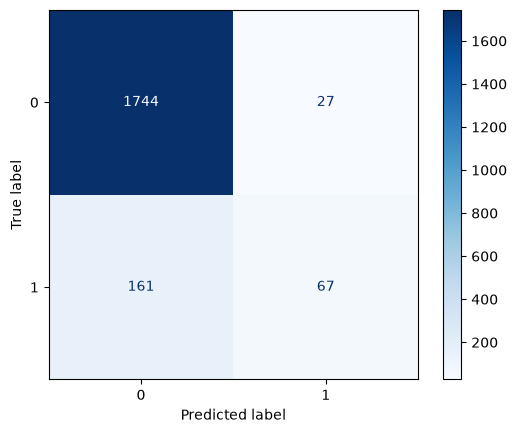

In [19]:
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.3f}")
print()
print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)
pd.DataFrame(
    cm,
    index=["actual_unsafe", "actual_safe"],
    columns=["pred_unsafe", "pred_safe"],
)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=logreg.classes_)
disp.plot(cmap="Blues")
plt.show()

A plotted confusion matrix gives the same information as the table, but it is often easier to scan visually because the diagonal highlights correct predictions and the off-diagonal cells show the mistakes.


This notebook showed the basic estimator workflow in scikit-learn: import, instantiate, fit, predict, and evaluate. In the next notebooks, we will look more closely at evaluation metrics and how to improve models through preprocessing and hyperparameter tuning.
